# Walkthrough: PSC



$$
t_{\mathrm{flight}}=\frac{L\lambda}{3956.0346}
$$

Use $L$ in metres, $\lambda$ in ångströms, and time in seconds.

In [1]:
from pathlib import Path
import mcstasscript as ms

instr = ms.McStas_instr(
    "PulseChopper",
    author="McStasScript example",
    origin="Teaching example",
)
mpi = 10


In [ ]:
from pathlib import Path
import mcstasscript as ms
import os, sys, shutil
from mcstasscript.interface.functions import Configurator

prefix = Path(sys.prefix)
guides = list(prefix.rglob('Guide.comp'))
mcstas_path = guides[0].parent.parent
config = Configurator()
config.set_mcstas_path(str(mcstas_path))
config.set_mcrun_path(str(Path(shutil.which('mcrun')).parent))
os.environ['MCSTAS'] = str(mcstas_path)

print('Python:', sys.executable)
print('McStas library:', mcstas_path)

## 1. Set the source timing

Define the source pulse duration, moderator timing parameters, repetition rate, and wavelength range here.

In [2]:
pulse_length = 400.0e-6
instr.add_parameter("pulse_length", value=pulse_length,
                    comment="Proton pulse duration for the moderator model [s]")
moderator_tau = 170.0e-6
instr.add_parameter("moderator_tau", value=moderator_tau,
                    comment="Cold moderator decay time used by Source_pulsed [s]")
moderator_n = 5.0
instr.add_parameter("moderator_n", value=moderator_n,
                    comment="Cold moderator pulse-shape parameter used by Source_pulsed")
moderator_time_center = 0.5*pulse_length + moderator_tau*(moderator_n+1.0)/moderator_n
source_frequency = 50.0
instr.add_parameter("source_frequency", value=source_frequency,
                    comment="Source repetition rate [Hz]")
lambda_min = 0.05
instr.add_parameter("lambda_min", value=lambda_min,
                    comment="Minimum source wavelength [Angstrom]")
lambda_max = 10.0
instr.add_parameter("lambda_max", value=lambda_max,
                    comment="Maximum source wavelength [Angstrom]")

l1 = 2.0
instr.add_parameter("l1", value=l1,
                    comment="Length of first guide segment [m]")


Parameter named: 'l1' with value: 2.0
 [dimensionless]
 Length of first guide segment [m]

## 2. Add the source and first guide

Run the next cell to create `Source_pulsed`, then place the guide entrance 0.1 m downstream. The source samples wavelength and emission time and assigns a weight using the moderator spectrum and time profile.

Read the source parameters in these groups before running the cell:

| Parameter | Value in this example | Meaning |
| --- | --- | --- |
| `xwidth`, `yheight` | 0.042 m, 0.03 m | Width and height of the emitting surface. |
| `Lmin`, `Lmax` | 0.5–10 Å | Wavelength sampling range; this is wider than the target chopper band. |
| `t_min`, `t_max` | 0–0.004 s | Emission-time sampling window. It includes the moderator tail; it is not the proton pulse duration. |
| `freq` | 50 Hz | Source repetition rate: one source period is 20 ms. |
| `t_pulse` | 400 µs | Proton pulse duration that drives the moderator model. |
| `dist` | 0.1 m | Distance to the focusing plane. |
| `focus_xw`, `focus_yh` | 0.04 m, 0.04 m | Size of the target at that plane, matching the guide entrance. |
| `T1` | 60 K | Temperature parameter for the cold moderator spectrum. |
| `I1` | `1.75e12/source_frequency` | Cold moderator intensity coefficient, scaled by the source rate in this example. |
| `tau1`, `n_mod` | 170 µs, 5 | Cold moderator decay-time and pulse-shape parameters. |
| `I_um` | `3.82e10/source_frequency` | Intensity coefficient for the additional moderator contribution. |
| `tau_um`, `n_um` | 12 µs, 5 | Timing and shape parameters for that contribution. |
| `chi_um`, `kap_um` | 0.9, 2.2 | Additional spectrum-shape parameters of the moderator model. |

1. The source emits over a finite time distribution. The timing code uses the approximate cold-moderator center
   $$\bar t_s=\frac{t_{\mathrm{pulse}}}{2}+\tau_1\frac{n+1}{n}=200+170\frac{6}{5}=404\;\mu\mathrm{s}.$$
   This is the timing reference used by the notebook, rather than the peak or full width of the complete source distribution.
2. A neutron travels at $v=3956.0346/\lambda$ m/s when $\lambda$ is in Å. Therefore its flight time is $t_{\mathrm{flight}}=L\lambda/3956.0346$ seconds.
3. Add emission time and flight time to predict its arrival at a downstream component: $t_{\mathrm{arrival}}\approx\bar t_s+L\lambda/3956.0346$.
4. The straight guide has 0.04 m entrance and exit dimensions, length `l1` = 2 m, and supermirror parameter `m` = 4. Its `AT` position marks its entrance, so its exit is 2.1 m from the source.


In [ ]:
source = instr.add_component("source", "Source_pulsed")
source.xwidth = 0.042
source.yheight = 0.03
source.Lmin = "lambda_min"
source.Lmax = "lambda_max"
source.t_min = 0.0
source.t_max = 0.004
source.dist = 0.1
source.focus_xw = 0.04
source.focus_yh = 0.04
source.freq = "source_frequency"
source.t_pulse = "pulse_length"
source.T1 = 60.0
source.I1 = "1.75e12/source_frequency"
source.tau1 = "moderator_tau"
source.n_mod = "moderator_n"
source.I_um = "3.82e10/source_frequency"
source.tau_um = 12.0e-6
source.n_um = 5.0
source.chi_um = 0.9
source.kap_um = 2.2

# Straight guide after the moderator. 


## 3. Measure the beam before the PSC


## 4. Run the beam without the PSC


---- Found 1 places in McStas output with keyword 'error'. 

[elitebook:236178] Set MCA parameter "orte_base_help_aggregate" to 0 to see all help / error messages
*** TRACE end *** 
Detector: lambda_before_PSC_I=3.71189e+10 lambda_before_PSC_ERR=1.0948e+08 lambda_before_PSC_N=6.43812e+06 "lambda_before_PSC.dat"
Detector: tof_before_PSC_I=3.74792e+10 tof_before_PSC_ERR=1.10392e+08 tof_before_PSC_N=6.44844e+06 "tof_before_PSC.dat"
INFO: Placing instr file copy PulseChopper.instr in dataset /home/kyriakos-karyos/Documents/SFN_TOF_INS_School/solutions/PSC/PulseChopper
INFO: Placing generated c-code copy PulseChopper.c in dataset /home/kyriakos-karyos/Documents/SFN_TOF_INS_School/solutions/PSC/PulseChopper

----------------------------------------------------------------------

INFO: Using directory: "/home/kyriakos-karyos/Documents/SFN_TOF_INS_School/solutions/PSC/PulseChopper"
INFO: Regenerating c-file: PulseChopper.c
Info:    'Source_pulsed' is a contributed component.
CFLAGS=

---------

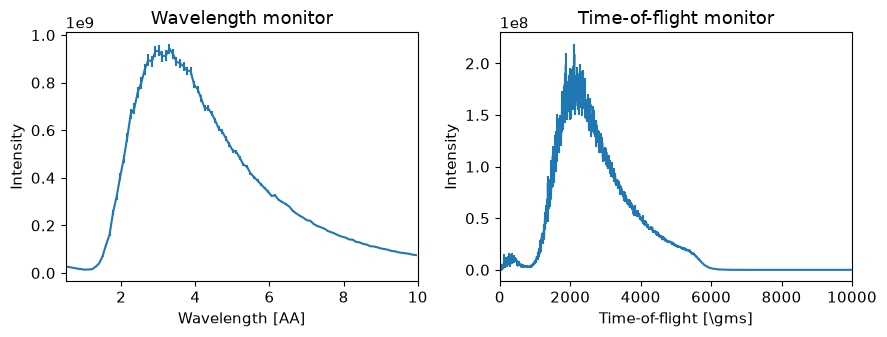

In [6]:
instr.settings(force_compile=True, ncount=1e8, mpi=mpi)
data=instr.backengine()
ms.make_sub_plot(data)

## 5. Add the pulse-shaping chopper

The calculations below use the settings in the parameter cell: source frequency $f_s=50$ Hz, order $q=1$, slit opening $\theta=45^\circ$, source-to-PSC distance $L=2.12$ m, and target band $[\lambda_{min},\lambda_{max}]=[2,8]$ Å. For neutrons, with wavelength in Å and distance in metres,

$$v=\frac{3956.0346}{\lambda}\;\mathrm{m\,s^{-1}},\qquad t_{flight}=\frac{L\lambda}{3956.0346}\;\mathrm{s}.$$

The `Source_pulsed` timing reference is its approximate emission-time center,

$$\bar t_s=\frac{t_{pulse}}{2}+\tau_1\frac{n+1}{n}=0.200+0.170\frac{6}{5}=0.404\;\mathrm{ms}.$$

This is a reference time, not the full source distribution; the moderator tail and pulse shape are not represented by a single center.

1. **Rotation and geometric opening.** The PSC runs at an integer harmonic of the source repetition rate:

   $$f_{PSC}=qf_s=1\times50=50\;\mathrm{Hz},\qquad T_{PSC}=\frac{1}{f_{PSC}}=20\;\mathrm{ms}.$$

   With one slit, one opening passes the beam per revolution. The angular fraction of a revolution that is open is $\theta/360^\circ$, so

   $$w_{PSC}=\frac{\theta}{360^\circ f_{PSC}}=\frac{45}{360\times50}=2.500\;\mathrm{ms}.$$

   This is the ideal geometric opening duration at the chopper; it is not automatically the measured TOF FWHM.

2. **Band-edge reference arrivals and phase.** For either wavelength edge, the reference arrival time at the chopper is

   $$t(\lambda)=\bar t_s+\frac{L\lambda}{3956.0346}.$$

   Thus

   $$t_2=0.404+\frac{2.12\times2}{3956.0346}=1.476\;\mathrm{ms},\qquad
   t_8=0.404+\frac{2.12\times8}{3956.0346}=4.691\;\mathrm{ms}.$$

   The band midpoint is $\bar\lambda=(\lambda_{min}+\lambda_{max})/2=5$ Å. Centering the opening on its reference arrival gives

   $$t_c=\frac{t_2+t_8}{2}=\bar t_s+\frac{L\bar\lambda}{3956.0346}=3.08345\;\mathrm{ms}.$$

   The opening repeats each rotor period, so wrap this delay into one period before converting to angle:

   $$\tau=t_c\bmod T_{PSC}=3.08345\;\mathrm{ms},\qquad
   \phi=\left(360^\circ f_{PSC}\tau\right)\bmod360^\circ=55.502^\circ.$$

   The instrument passes $\phi$ to `DiskChopper.phase`.

3. **Check whether the slit can pass the requested band.** The flight-time difference between the wavelength edges is

   $$\Delta t_\lambda=t_8-t_2=\frac{L(\lambda_{max}-\lambda_{min})}{3956.0346}
   =\frac{2.12(8-2)}{3956.0346}=3.215\;\mathrm{ms}.$$

   A nominal window covering both the proton pulse and that wavelength spread is

   $$w_{req}=t_{pulse}+\Delta t_\lambda=0.400+3.215=3.615\;\mathrm{ms}.$$

   Since $w_{PSC}=2.500\;\mathrm{ms}<w_{req}$, the full band is expected to clip. The largest integer source harmonic that could cover this estimate is

   $$q_{max}=\left\lfloor\frac{\theta}{360^\circ f_s w_{req}}\right\rfloor
   =\left\lfloor\frac{45}{360\times50\times0.003615}\right\rfloor=0.$$

   Thus no positive harmonic with this slit angle covers the full estimated pulse-plus-band span.

   For an instantaneous source pulse, convert the opening duration back to a wavelength width:

   $$\Delta\lambda_{gate}=\frac{3956.0346w_{PSC}}{L}=4.665\;\mathrm{\AA},\qquad
   \lambda_{gate}\approx\bar\lambda\pm\frac{\Delta\lambda_{gate}}{2}
   =2.67\text{--}7.33\;\mathrm{\AA}.$$

   The angle required for the wavelength spread alone is

   $$\theta_{min,\lambda}=360^\circ f_{PSC}\Delta t_\lambda=57.88^\circ.$$

   Including the 0.400 ms proton pulse gives the nominal requirement

   $$\theta_{min}=360^\circ f_{PSC}w_{req}=65.08^\circ.$$

   These are ideal estimates. The full moderator time distribution and finite beam footprint can broaden the measured profile further.

### Declare the PSC timing variables

`add_declare_var("double", name)` declares a floating-point variable in the generated McStas instrument. It does not calculate its value. `append_initialize(...)` adds C code that calculates these values once at the start of each simulation, using the current instrument parameters.

| Variable | Meaning and units |
| --- | --- |
| `PSC_order` | Integer source harmonic copied from `psc_order`, stored as a double. |
| `nu_PSC` | Rotation frequency: `PSC_order * source_frequency` [Hz]. |
| `actual_width_PSC` | Geometric opening time: `opening_PSC / (360 * nu_PSC)` [s]. |
| `psc_source_center` | Approximate Source_pulsed emission-time center [s]. |
| `psc_band_min`, `psc_band_max` | Target wavelength edges [Å], in the PSC-only notebook. |
| `psc_phase_lambda` | Midpoint of the 2–8 Å target edges [Å]. |
| `psc_t_start`, `psc_t_end` | Reference arrival times of the lower and upper wavelength edges [s]. |
| `psc_target_width` | Nominal proton-pulse duration plus band flight-time spread [s]. |
| `psc_max_order` | Largest integer harmonic whose geometric opening covers that nominal span. |
| `psc_phase_time` | Desired opening-center delay, the midpoint of the 2 and 8 Å reference arrivals [s]. |
| `psc_phase_deg` | That delay converted to an angle, modulo 360 [degrees]. |

Run the declarations first, then register the calculations in the following cell.


## 5. Declare PSC parameters


## 6. Register (Initialise) the PSC calculations and checks


## 7. Create the PSC component



## 8. Measure the beam after the PSC

## 9. Inspect the instrument geometry

In [ ]:
# instr.show_diagram()
# instr.write_full_instrument()
# %matplotlib widget
# #replace "kirikarios" with your username!
# import sys; sys.path.insert(0, '/home/kirikarios/.conda/envs/mcstas/share/mcstas/tools/Python/mcdisplay/plopp')
# import mcdisplopp; mcdisplopp.ui('/home/kirikarios/Documents/PulseChopper.instr', 100, '')

## 10. Run the chopper model


---- Found 1 places in McStas output with keyword 'error'. 

[elitebook:236456] Set MCA parameter "orte_base_help_aggregate" to 0 to see all help / error messages
*** TRACE end *** 
Detector: lambda_before_PSC_I=3.73511e+10 lambda_before_PSC_ERR=1.1029e+08 lambda_before_PSC_N=6.43976e+06 "lambda_before_PSC.dat"
Detector: tof_before_PSC_I=3.76886e+10 tof_before_PSC_ERR=1.11093e+08 tof_before_PSC_N=6.45016e+06 "tof_before_PSC.dat"
Detector: lambda_after_PSC_I=2.64823e+10 lambda_after_PSC_ERR=8.73277e+07 lambda_after_PSC_N=917050 "lambda_after_PSC.dat"
Detector: tof_after_PSC_I=2.64823e+10 tof_after_PSC_ERR=8.73277e+07 tof_after_PSC_N=922903 "tof_after_PSC.dat"
INFO: Placing instr file copy PulseChopper.instr in dataset /home/kyriakos-karyos/Documents/SFN_TOF_INS_School/solutions/PSC/PulseChopper_0
INFO: Placing generated c-code copy PulseChopper.c in dataset /home/kyriakos-karyos/Documents/SFN_TOF_INS_School/solutions/PSC/PulseChopper_0

--------------------------------------------------

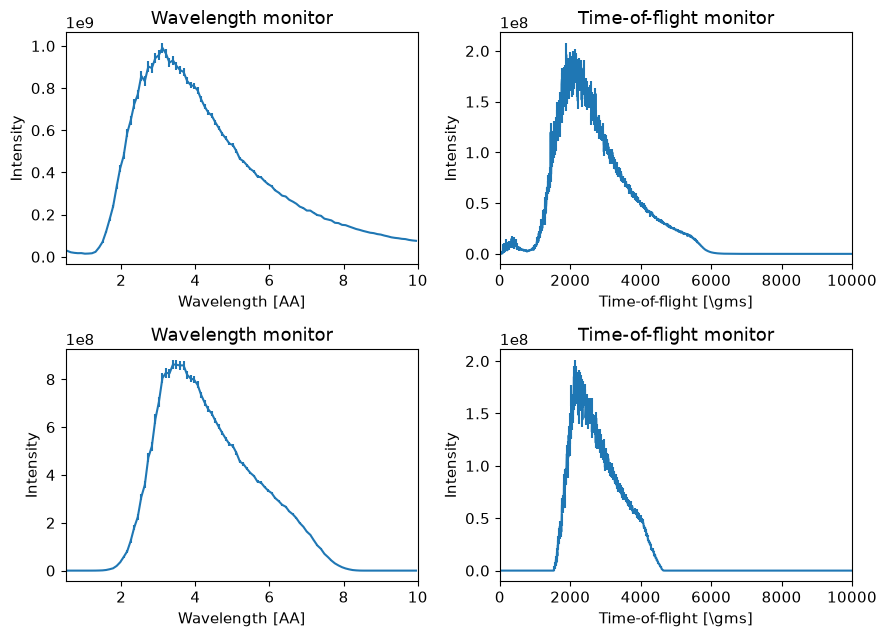

In [ ]:
# instr.settings(force_compile=True, ncount=1e8, mpi=mpi)
# data=instr.backengine()
# ms.make_sub_plot(data)

## 11. Compare one pulse

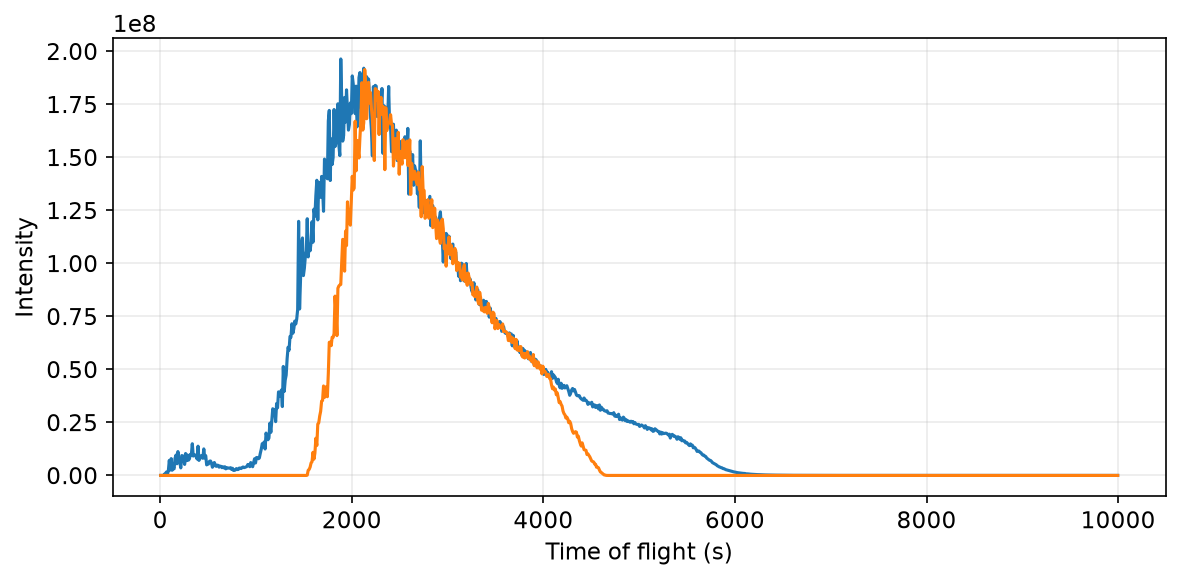

In [13]:
import matplotlib.pyplot as plt

before = next(d for d in data if d.name == "tof_before_PSC")
after = next(d for d in data if d.name == "tof_after_PSC")

plt.figure(figsize=(8, 4), dpi=150)

plt.plot(before.xaxis, before.Intensity)
plt.plot(after.xaxis, after.Intensity)

plt.xlabel("Time of flight (s)")
plt.ylabel("Intensity")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 12. Change the PSC frequency

**Do:** Run the sweep to compare several integer source harmonics. It keeps the slit angle and source frequency fixed, and changes only $q$.

